# Image Processing 2: Retinal Vessel Segmentation

**Part A** segments the blood vessels in a colour fundus image by thresholding the hue channel and
cleaning the mask, and compares the result with a manual annotation (Dice score).

**Part B** works on the manual annotation: it removes vessels narrower than 8 pixels, thins the rest
to a 1-pixel centreline, measures its length and plots the distribution of vessel orientations.

Built with scikit-image.

## A. Vessel segmentation

### Colour channels

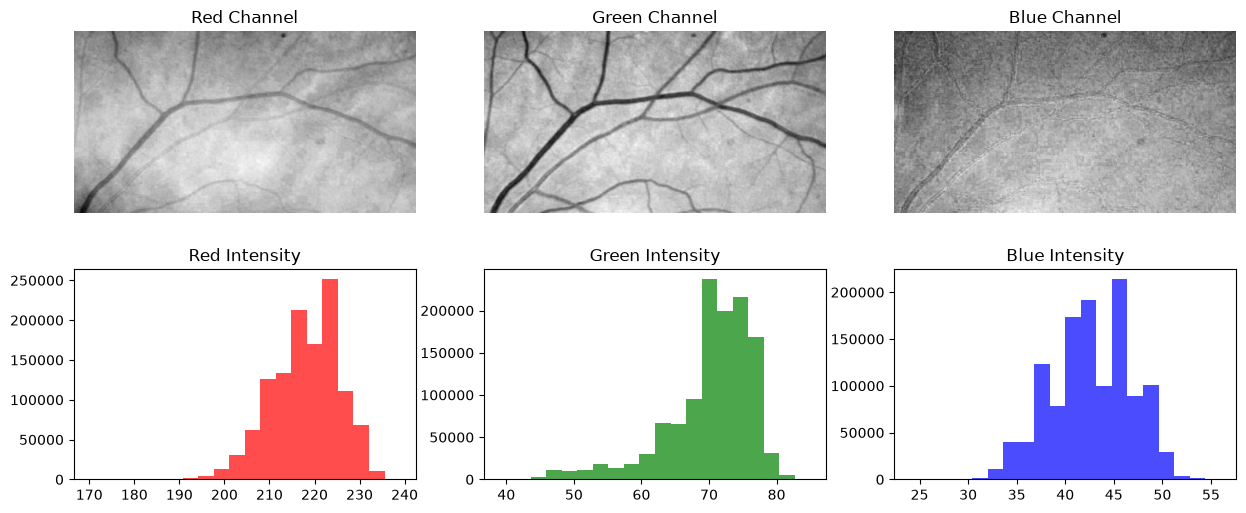

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from skimage import color, filters, img_as_bool, io
from skimage.filters import threshold_otsu
from skimage.morphology import binary_closing, binary_opening, disk, remove_small_objects, thin

# Fundus image and its manual vessel annotation (course data, not included in this repository)
im = io.imread("fundus.jpg")
manual_mask = img_as_bool(io.imread("fundus_vessel_mask.jpg"))  # JPEG, so threshold at half intensity

r_im, g_im, b_im = im[:, :, 0], im[:, :, 1], im[:, :, 2]

plt.figure(figsize=(15, 6))
plt.subplot(2, 3, 1); plt.imshow(r_im, cmap="gray"); plt.title("Red Channel"); plt.axis("off")
plt.subplot(2, 3, 2); plt.imshow(g_im, cmap="gray"); plt.title("Green Channel"); plt.axis("off")
plt.subplot(2, 3, 3); plt.imshow(b_im, cmap="gray"); plt.title("Blue Channel"); plt.axis("off")
plt.subplot(2, 3, 4); plt.hist(r_im.ravel(), bins=20, color="r", alpha=0.7); plt.title("Red Intensity")
plt.subplot(2, 3, 5); plt.hist(g_im.ravel(), bins=20, color="g", alpha=0.7); plt.title("Green Intensity")
plt.subplot(2, 3, 6); plt.hist(b_im.ravel(), bins=20, color="b", alpha=0.7); plt.title("Blue Intensity")
plt.show()

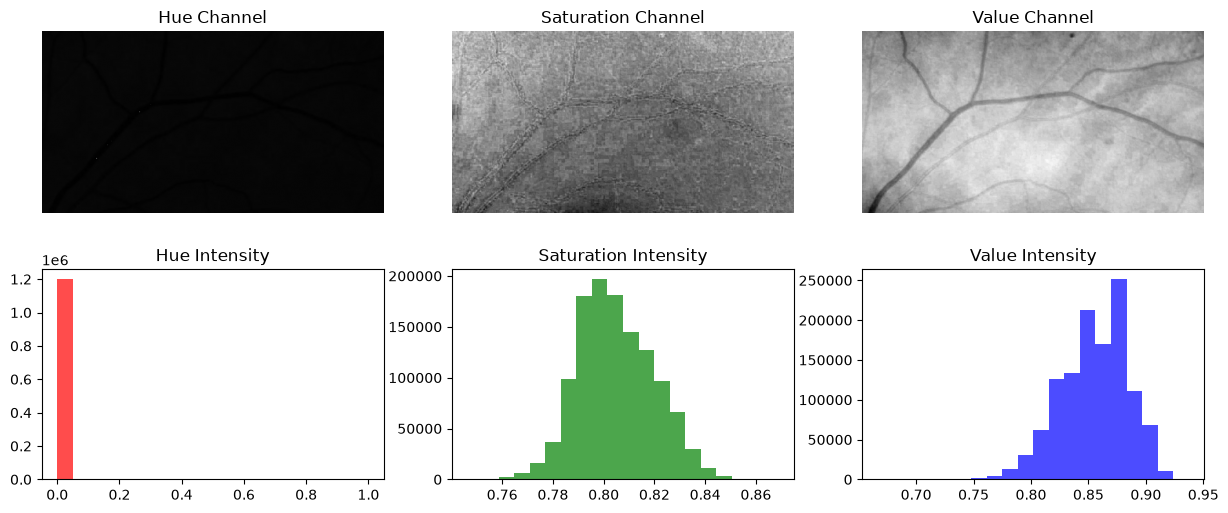

In [2]:
# Convert to HSV and separate the H, S and V channels
hsv_im = color.rgb2hsv(im) 
h_im = hsv_im[:,:,0]
s_im = hsv_im[:,:,1]
v_im = hsv_im[:,:,2]

# Display three channels separately in subplots with the corresponding intensity histograms
plt.figure(figsize=(15,6))
plt.subplot(2,3,1); plt.imshow(h_im, cmap='gray'); plt.title('Hue Channel'); plt.axis('off')
plt.subplot(2,3,2); plt.imshow(s_im, cmap='gray'); plt.title('Saturation Channel'); plt.axis('off')
plt.subplot(2,3,3); plt.imshow(v_im, cmap='gray'); plt.title('Value Channel'); plt.axis('off')
plt.subplot(2,3,4); plt.hist(h_im.ravel(), bins=20, color='r', alpha=0.7); plt.title('Hue Intensity')
plt.subplot(2,3,5); plt.hist(s_im.ravel(), bins=20, color='g', alpha=0.7); plt.title('Saturation Intensity')
plt.subplot(2,3,6); plt.hist(v_im.ravel(), bins=20, color='b', alpha=0.7); plt.title('Value Intensity')

plt.show()

### Threshold and clean-up

Hue threshold_otsu value: 0.021463


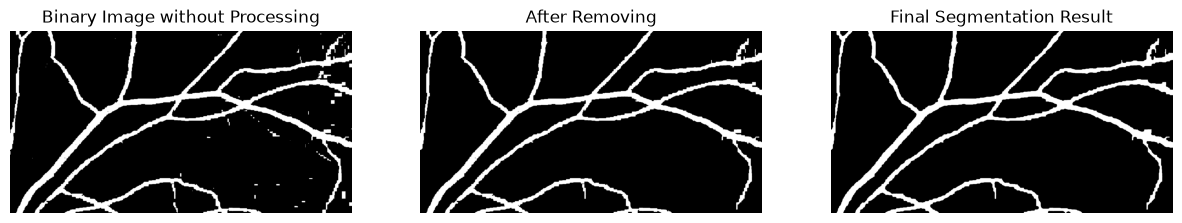

In [3]:
# Vessels are darker red than the background, which shows best in the hue channel.
# Otsu's threshold on hue is printed for reference; 0.022 (just above it) worked slightly better.
h_threshold = threshold_otsu(h_im)
vessels = h_im < 0.022

vessels_removed = remove_small_objects(vessels, min_size=520)
vessels_pro = binary_closing(vessels_removed, disk(5))

print(f"Hue threshold_otsu value: {h_threshold:.6f}")
plt.figure(figsize=(15, 8))
plt.subplot(1, 3, 1); plt.imshow(vessels, cmap="gray"); plt.title("Binary Image without Processing"); plt.axis("off")
plt.subplot(1, 3, 2); plt.imshow(vessels_removed, cmap="gray"); plt.title("After Removing"); plt.axis("off")
plt.subplot(1, 3, 3); plt.imshow(vessels_pro, cmap="gray"); plt.title("Final Segmentation Result"); plt.axis("off")
plt.show()

### Comparison with the manual annotation

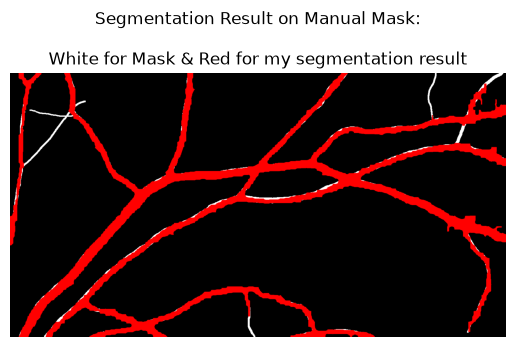

In [4]:
v_overlay = np.zeros((*vessels_pro.shape, 3), dtype=np.uint8)
v_overlay[manual_mask] = [255, 255, 255]  # manual annotation in white
v_overlay[vessels_pro] = [255, 0, 0]      # own segmentation in red

plt.imshow(v_overlay)
plt.title("Segmentation Result on Manual Mask:\n\nWhite for Mask & Red for my segmentation result")
plt.axis("off")
plt.show()

In [5]:
intersection = np.sum(vessels_pro & manual_mask)
dice_val = 2 * intersection / (np.sum(vessels_pro) + np.sum(manual_mask))
print(f"Dice Score: {dice_val:.6f}")

Dice Score: 0.770117


## B. Centreline of the annotated vessel network

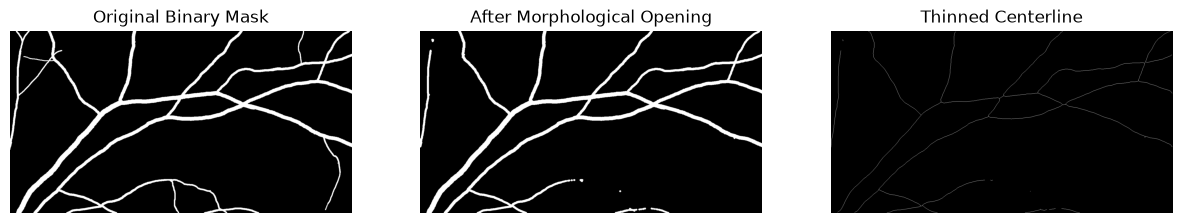

In [6]:
# Steps below use the manual annotation, not the own segmentation
opened_mask = binary_opening(manual_mask, disk(4))  # removes vessels narrower than 8 pixels
thinned_mask = thin(opened_mask)                    # 1-pixel centreline

plt.figure(figsize=(15, 8))
plt.subplot(1, 3, 1); plt.imshow(manual_mask, cmap="gray"); plt.title("Original Binary Mask"); plt.axis("off")
plt.subplot(1, 3, 2); plt.imshow(opened_mask, cmap="gray"); plt.title("After Morphological Opening"); plt.axis("off")
plt.subplot(1, 3, 3); plt.imshow(thinned_mask, cmap="gray"); plt.title("Thinned Centerline"); plt.axis("off")
plt.show()

In [7]:
vascular_length = np.sum(thinned_mask)
print(f"Vascular Length: {vascular_length} pixels")

Vascular Length: 6198 pixels


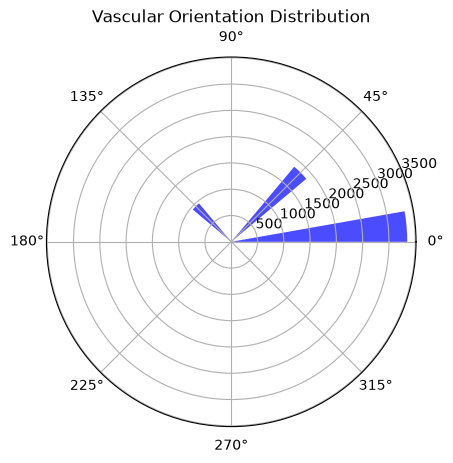

In [8]:
# Local orientation of the centreline from Sobel gradients.
# sobel_h responds to changes along rows and sobel_v to changes along columns. Passing them to
# arctan2 in this order gives the direction along the line (perpendicular to the gradient),
# measured with the y axis pointing up as in the displayed image.
d_row = filters.sobel_h(thinned_mask)
d_col = filters.sobel_v(thinned_mask)
angles = np.rad2deg(np.arctan2(d_col, d_row)) % 180
angles = angles[thinned_mask]

num_bins = 18
hist, bin_edges = np.histogram(angles, bins=num_bins, range=(0, 180))
bin_centers = np.deg2rad((bin_edges[:-1] + bin_edges[1:]) / 2)

plt.subplot(projection="polar")
plt.bar(bin_centers, hist, width=np.pi / num_bins, color="b", alpha=0.7)
plt.title("Vascular Orientation Distribution")
plt.show()